<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-06-explainability.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "Explainability for Data-Centric AI"
bibliography:
  - refs/refs.bib
---

In [2]:
#| echo: false
%pip install -q shap

import warnings
from itertools import combinations
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

Note: you may need to restart the kernel to use updated packages.


# Learning outcomes

By the end of this 3-hour lab, you should be able to:

- Explain the SHAP baseline, the value function $v(S)$, and feature contributions.
- Compute exact Shapley values by brute force and check them against the `shap` library.
- Interpret global and local SHAP results, and compare SHAP with permutation importance.
- Use explanations to detect **leakage**, **shortcuts**, and **proxies** in a real dataset.
- Detect **label errors** with out-of-fold predictions and inspect them with local explanations.
- Value training data with **KNN-Shapley** and test the value by removing data.
- Generate simple **counterfactual** explanations and spot proxy-based recourse.

# Lab plan

| Time | Part |
| --- | --- |
| 0:00-0:50 | Part A: SHAP from first principles on a small flight-delay model |
| 0:50-1:30 | Part B: a dirty Adult Income dataset; find leakage and shortcuts with explanations |
| 1:30-1:40 | Break |
| 1:40-2:10 | Part C: label errors |
| 2:10-2:40 | Part D: data valuation with KNN-Shapley |
| 2:40-2:55 | Part E: counterfactuals and proxies |
| 2:55-3:00 | Data bug report |

The theory is in the slides *Explainable AI for Data-Centric AI* [@lundberg2017unified; @molnar2022interpretable].

# Part A: SHAP from first principles

# 1. Global and local explanations

Model explainability answers two related questions:

- **Global explanation:** which features does the fitted model rely on across many predictions?
- **Local explanation:** which feature values moved one prediction away from the model's baseline?

SHAP connects these views by calculating a contribution for every feature and every observation.

# 2. A fitted flight-delay model {.scrollable}

The example uses a decision tree trained on five synthetic flight features. The model remains fixed throughout the SHAP analysis.

The synthetic data keeps the example reproducible. The SHAP procedure is the same for a tree trained on real flight data.

In [3]:
#| echo: false
rng = np.random.default_rng(RANDOM_STATE)
n_flights = 2_000

bad_weather = rng.binomial(1, 0.25, n_flights)
departure_hour = rng.integers(0, 24, n_flights)
is_holiday = rng.binomial(1, 0.12, n_flights)
scheduled_duration_min = np.clip(rng.normal(120, 35, n_flights), 40, 300)
late_departure_probability = np.clip(
    0.10 + 0.45 * bad_weather + 0.15 * is_holiday,
    0,
    0.95,
)
late_departure = rng.binomial(1, late_departure_probability)

logit = (
    -2.3
    + 2.2 * bad_weather
    + 1.8 * late_departure
    + 0.7 * is_holiday
    + 0.006 * (scheduled_duration_min - 120)
    + 0.03 * np.abs(departure_hour - 12)
)
delay_probability = 1 / (1 + np.exp(-logit))
delayed = rng.binomial(1, delay_probability)

X = pd.DataFrame({
    "bad_weather": bad_weather,
    "late_departure": late_departure,
    "departure_hour": departure_hour,
    "is_holiday": is_holiday,
    "scheduled_duration_min": scheduled_duration_min,
})
y = pd.Series(delayed, name="delayed")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE,
)

tree = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=30,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)

pd.DataFrame({
    "metric": ["balanced accuracy", "F1"],
    "value": [
        balanced_accuracy_score(y_test, y_pred),
        f1_score(y_test, y_pred),
    ],
})

,metric,value
0,balanced accuracy,0.755526
1,F1,0.664865


# 3. SHAP values

SHAP explains how a **fixed, already-trained model** produced a prediction.

For one observation, SHAP divides the difference between the model's baseline output and its prediction among the features:

$$f(x) = E[f(X)] + \phi_1 + \phi_2 + \cdots + \phi_p$$

- $E[f(X)]$ is the **baseline**, the model's expected output for the reference population.
- $\phi_j$ is the contribution assigned to feature $j$ for this observation.
- Positive contributions increase the output. Negative contributions decrease it.

SHAP explains the model's behavior. A large contribution does not prove that the feature caused the outcome.

# 4. The SHAP baseline

Choose a representative **reference dataset**, ask the model to predict every row, and average those outputs:

$$E[f(X)] \approx \frac{1}{n}\sum_{i=1}^{n}f(x_i)$$

| Reference flight | Predicted delay probability |
|---|---:|
| A | 0.10 |
| B | 0.20 |
| C | 0.30 |
| D | 0.60 |

The baseline is $(0.10 + 0.20 + 0.30 + 0.60)/4 = 0.30$. SHAP starts every explanation from this model output.

The baseline is the average **prediction**, not the observed delay rate. The two may differ when the model is not perfectly calibrated.

# 5. Known and unknown features

SHAP reveals the feature values of the observation being explained one group at a time.

- A **known feature** is fixed to this observation's value.
- An **unknown feature** is averaged out using the reference distribution. SHAP does not replace it with zero.

Consider a flight with bad weather and a late departure:

| Information revealed | Expected model output |
|---|---:|
| Nothing about this flight | $v(\varnothing)=0.30$ |
| Bad weather only | $v(W)=0.50$ |
| Late departure only | $v(L)=0.40$ |
| Both feature values | $v(W,L)=0.70$ |

$v(S)$ is the expected model output when the features in set $S$ are fixed and the remaining features are averaged out.

# 6. Computing a SHAP contribution

A feature's effect can depend on which other features are already known. SHAP therefore averages its marginal contribution across the possible feature orders.

For **weather**:

$$W \text{ first}: \quad v(W)-v(\varnothing)=0.50-0.30=0.20$$

$$W \text{ after }L: \quad v(W,L)-v(L)=0.70-0.40=0.30$$

$$\phi_W = \frac{0.20+0.30}{2}=0.25$$

Similarly, $\phi_L=0.15$. The contributions reconstruct the prediction:

$$0.70 = 0.30 + 0.25 + 0.15$$

# 7. All feature contexts

For feature $j$, exact Shapley values consider every subset $S$ that does not contain $j$:

$$\phi_j = \sum_{S \subseteq N \setminus \{j\}} \frac{|S|!(M-|S|-1)!}{M!} \left[v(S \cup \{j\})-v(S)\right]$$

The bracketed term measures what changes when feature $j$ becomes known in context $S$. The weight treats every possible feature order equally.

With $M$ features, each feature has $2^{M-1}$ possible subsets of the other features. For 10 features this is 512 subsets per feature. For 20 features it is 524,288. Direct enumeration quickly becomes impractical.

# 8. Exact Shapley values by brute force {.scrollable}

With only five features we *can* enumerate all $2^5 = 32$ coalitions. We use the **interventional** value function: features in $S$ are fixed to the explained flight, the others are taken from each background flight, and predictions are averaged:

$$v_x(S) = \frac{1}{|B|}\sum_{z \in B} f(x_S, z_{\bar S})$$

Then we apply the Shapley formula directly.

In [4]:
background = X_train.sample(100, random_state=RANDOM_STATE)
x_explain = X_test.iloc[0]
features = list(X.columns)
M = len(features)


def predict_delay(frame):
    frame = frame if isinstance(frame, pd.DataFrame) else pd.DataFrame(frame, columns=features)
    return tree.predict_proba(frame[features])[:, 1]


def value(coalition):
    """Expected prediction when the features in `coalition` are known."""
    hybrid = background.copy()
    for feature in coalition:
        hybrid[feature] = x_explain[feature]
    return predict_delay(hybrid).mean()


v = {frozenset(s): value(s) for k in range(M + 1) for s in combinations(features, k)}

exact_phi = {}
for j in features:
    others = [f for f in features if f != j]
    exact_phi[j] = sum(
        factorial(len(s)) * factorial(M - len(s) - 1) / factorial(M)
        * (v[frozenset(s) | {j}] - v[frozenset(s)])
        for k in range(M) for s in combinations(others, k)
    )

print(f"coalitions evaluated: {len(v)}")
print(f"baseline v(empty) = {v[frozenset()]:.4f}")
print(f"prediction f(x)   = {predict_delay(x_explain.to_frame().T)[0]:.4f}")
print(f"baseline + sum(phi) = {v[frozenset()] + sum(exact_phi.values()):.4f}  (efficiency)")
pd.Series(exact_phi, name="exact_phi").round(4)

coalitions evaluated: 32
baseline v(empty) = 0.4357
prediction f(x)   = 0.2363
baseline + sum(phi) = 0.2363  (efficiency)


bad_weather              -0.1166
late_departure           -0.0739
departure_hour           -0.0070
is_holiday                0.0000
scheduled_duration_min   -0.0020
Name: exact_phi, dtype: float64

# 9. The library gives the same numbers {.scrollable}

`TreeExplainer` with the same background data and `feature_perturbation="interventional"` computes the same game exactly, using the tree structure instead of enumeration [@lundberg2020local]. Model-agnostic explainers *estimate* it from samples [@strumbelj2014explaining].

In [5]:
import shap

tree_explainer = shap.TreeExplainer(tree, data=background, feature_perturbation="interventional",
                                    model_output="probability")
tree_phi = np.asarray(tree_explainer.shap_values(x_explain.to_frame().T))
tree_phi = tree_phi[..., 1].ravel() if tree_phi.ndim == 3 else tree_phi.ravel()

permutation_explainer = shap.PermutationExplainer(predict_delay, background)
perm_phi = permutation_explainer(x_explain.to_frame().T, max_evals=200).values.ravel()

kernel_explainer = shap.KernelExplainer(predict_delay, background)
kernel_phi = np.asarray(kernel_explainer.shap_values(x_explain.to_frame().T, nsamples=64, silent=True)).ravel()

pd.DataFrame({
    "brute force": pd.Series(exact_phi),
    "TreeSHAP (interventional)": tree_phi,
    "PermutationExplainer": perm_phi,
    "KernelSHAP": kernel_phi,
}, index=features).round(4)

,brute force,TreeSHAP (interventional),PermutationExplainer,KernelSHAP
bad_weather,-0.1166,-0.1166,-0.1165,-0.1166
late_departure,-0.0739,-0.0739,-0.0747,-0.0739
departure_hour,-0.0070,-0.0070,-0.0077,-0.0070
is_holiday,0.0000,0.0000,0.0000,0.0000
scheduled_duration_min,-0.0020,-0.0020,-0.0005,-0.0020


# Checkpoint: Shapley computations

1. Why do brute force and TreeSHAP agree exactly, while the sampling explainers may differ slightly?
2. Replace `background` with 100 flights that all had bad weather. How do the baseline and $\phi_{\text{bad weather}}$ change? Why?
3. How many coalitions would brute force need for the 14 features of Adult Income?

# 10. How the SHAP library performs the calculation

SHAP normally keeps the fitted model fixed. It does **not retrain one model for every feature subset**.

- `TreeExplainer` uses the fitted tree's paths and stored sample counts to calculate contributions efficiently.
- `LinearExplainer` uses the fitted coefficients and the background feature distribution.
- `KernelExplainer` and `PermutationExplainer` approximate the result by evaluating selected coalitions or feature orders with the existing prediction function.

This differs from wrapper selection such as SFS. SFS repeatedly retrains models to choose features. SHAP explains predictions from one fitted model.

The reference data still matters: changing the background population can change the baseline and the SHAP contributions.

# 11. Global SHAP importance {.scrollable}

A local SHAP value explains one prediction. Global importance averages the absolute local contributions over many observations:

$$I_j = \frac{1}{n}\sum_{i=1}^{n}|\phi_{ij}|$$

Absolute values prevent positive and negative effects from cancelling. The result measures how strongly the fitted model uses each feature on average.

SHAP baseline for the delayed class: 0.500


,feature,mean_abs_shap
0,bad_weather,0.222251
1,late_departure,0.097423
2,scheduled_duration_min,0.029248
3,departure_hour,0.019365
4,is_holiday,0.000000


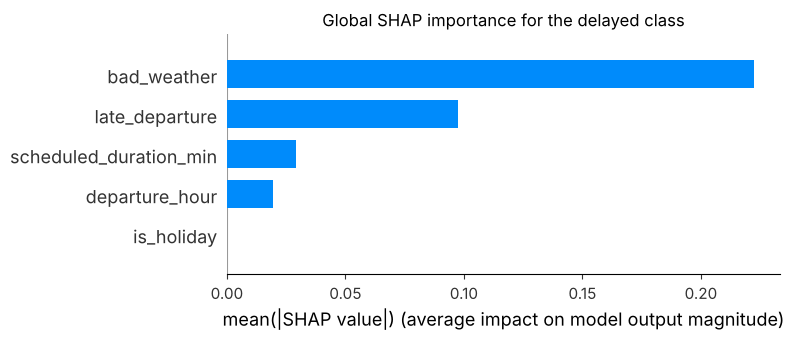

In [6]:
#| echo: false
import shap

X_shap = X_test.reset_index(drop=True)
explainer = shap.TreeExplainer(tree)
raw_shap_values = explainer.shap_values(X_shap)

# Different SHAP versions return binary-class explanations in different shapes.
if isinstance(raw_shap_values, list):
    shap_values_positive_class = raw_shap_values[1]
else:
    shap_values_array = np.asarray(raw_shap_values)
    if shap_values_array.ndim == 3:
        shap_values_positive_class = shap_values_array[:, :, 1]
    else:
        shap_values_positive_class = shap_values_array

expected_values = np.asarray(explainer.expected_value)
baseline_positive_class = float(
    expected_values[1] if expected_values.size > 1 else expected_values.item()
)
print(f"SHAP baseline for the delayed class: {baseline_positive_class:.3f}")

shap_importance = (
    pd.DataFrame({
        "feature": X_shap.columns,
        "mean_abs_shap": np.abs(shap_values_positive_class).mean(axis=0),
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)
display(shap_importance)

shap.summary_plot(
    shap_values_positive_class,
    X_shap,
    plot_type="bar",
    show=False,
)
plt.title("Global SHAP importance for the delayed class")
plt.tight_layout()
plt.show()

# 12. Beeswarm: direction and spread {.scrollable}

The bar chart hides **direction**. The beeswarm plot shows every $\phi_{ij}$, coloured by the feature value: red points on the right mean "high values push the prediction up".

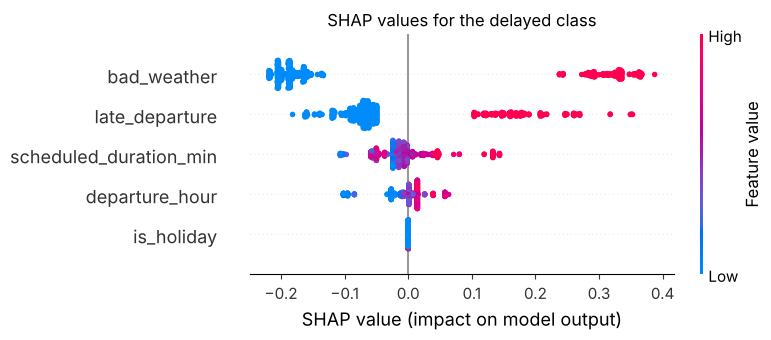

In [7]:
shap.summary_plot(shap_values_positive_class, X_shap, show=False)
plt.title("SHAP values for the delayed class")
plt.tight_layout()
plt.show()

# 13. SHAP importance vs permutation importance {.scrollable}

Permutation importance measures the **drop in performance** when a feature is shuffled [@breiman2001random; @fisher2019all]; SHAP importance measures how much the **output** moves. They usually agree on the top features but answer different questions.

In [8]:
perm = permutation_importance(tree, X_test, y_test, scoring="balanced_accuracy",
                              n_repeats=10, random_state=RANDOM_STATE)
comparison = pd.DataFrame({
    "mean_abs_shap": pd.Series(np.abs(shap_values_positive_class).mean(axis=0), index=X_shap.columns),
    "permutation_importance": pd.Series(perm.importances_mean, index=X_test.columns),
}).sort_values("mean_abs_shap", ascending=False)
comparison.round(4)

,mean_abs_shap,permutation_importance
bad_weather,0.2223,0.1765
late_departure,0.0974,0.0320
scheduled_duration_min,0.0292,0.0081
departure_hour,0.0194,0.0000
is_holiday,0.0000,0.0000


# 14. Local SHAP explanation {.scrollable}

Global importance summarizes many predictions.

- A local SHAP explanation focuses on one row and shows which selected features pushed the model toward or away from the delayed-flight class.
- Positive SHAP values increase the delayed-class output for this observation.
- Negative SHAP values decrease it.

In [9]:
#| echo: false
row_id = 0
predicted_delay_probability = tree.predict_proba(X_shap.iloc[[row_id]])[0, 1]
reconstructed_output = (
    baseline_positive_class + shap_values_positive_class[row_id].sum()
)

display(pd.DataFrame({
    "quantity": [
        "baseline",
        "sum of SHAP contributions",
        "reconstructed output",
        "model prediction",
    ],
    "value": [
        baseline_positive_class,
        shap_values_positive_class[row_id].sum(),
        reconstructed_output,
        predicted_delay_probability,
    ],
}))

local_shap = (
    pd.DataFrame({
        "feature": X_shap.columns,
        "feature_value": X_shap.iloc[row_id].to_numpy(),
        "shap_contribution": shap_values_positive_class[row_id],
    })
    .assign(abs_contribution=lambda frame: frame["shap_contribution"].abs())
    .sort_values("abs_contribution", ascending=False)
    .drop(columns="abs_contribution")
    .reset_index(drop=True)
)
local_shap

,quantity,value
0,baseline,0.500000
1,sum of SHAP contributions,-0.263709
2,reconstructed output,0.236291
3,model prediction,0.236291


,feature,feature_value,shap_contribution
0,bad_weather,0.00000,-0.188086
1,late_departure,0.00000,-0.064150
2,departure_hour,5.00000,-0.009704
3,scheduled_duration_min,111.66959,-0.001770
4,is_holiday,0.00000,0.000000


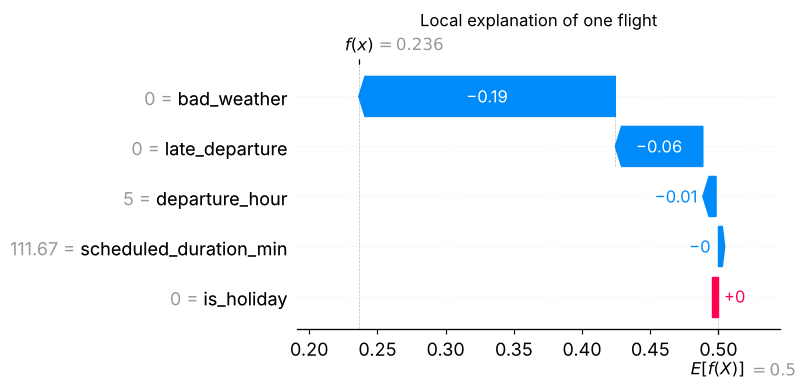

In [10]:
explanation = shap.Explanation(
    values=shap_values_positive_class[row_id],
    base_values=baseline_positive_class,
    data=X_shap.iloc[row_id].to_numpy(),
    feature_names=list(X_shap.columns),
)
shap.plots.waterfall(explanation, show=False)
plt.title("Local explanation of one flight")
plt.tight_layout()
plt.show()

# Part B: explanations as data-debugging tools

# 15. A dirty Adult Income dataset {.scrollable}

A colleague hands you an extended version of Adult Income (predict income > 50K) with two extra columns collected by the data team:

- `income_band_code`: a code from the payroll system;
- `form_version`: which version of the survey form was used.

The model will be used on **new survey respondents** (the *deployment* set). The next cell prepares the data and **injects hidden problems**: try not to read it before finishing Part B.

In [11]:
#| echo: false
# INSTRUCTOR CELL: builds the dirty dataset. Try not to read it before the end of Part B.
def load_adult(n_rows=8000):
    adult = fetch_openml("adult", version=2, as_frame=True)
    df = adult.frame.copy()
    df.columns = [c.strip().lower().replace("-", "_") for c in df.columns]
    df = df.rename(columns={"class": "income"}).replace("?", np.nan).dropna()
    df["income"] = (df["income"].astype(str).str.strip().str.rstrip(".") == ">50K").astype(int)
    return df.sample(n=min(n_rows, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)


adult = load_adult()
rng = np.random.default_rng(RANDOM_STATE)

train_df, rest_df = train_test_split(adult, test_size=0.5, stratify=adult["income"], random_state=RANDOM_STATE)
valid_df, deploy_df = train_test_split(rest_df, test_size=0.5, stratify=rest_df["income"], random_state=RANDOM_STATE)
train_df, valid_df, deploy_df = (d.reset_index(drop=True).copy() for d in (train_df, valid_df, deploy_df))

# Problem 1, leakage: the payroll code is recorded AFTER the income is known (95% agreement).
# For new respondents it does not exist yet, so the system fills it with the "unknown" code -1.
for d in (train_df, valid_df):
    d["income_band_code"] = np.where(rng.random(len(d)) < 0.95, d["income"], 1 - d["income"])
deploy_df["income_band_code"] = -1

# Problem 2, shortcut: during the historical campaign, the new form (1) was mostly sent to
# high earners. For new respondents the form version is assigned at random.
for d in (train_df, valid_df):
    d["form_version"] = np.where(rng.random(len(d)) < 0.85, d["income"], 1 - d["income"])
deploy_df["form_version"] = rng.integers(0, 2, len(deploy_df))

# Problem 3, label noise: 10% of the TRAINING labels are flipped (data-entry errors).
flipped = rng.random(len(train_df)) < 0.10
train_df["income_observed"] = np.where(flipped, 1 - train_df["income"], train_df["income"])
valid_df["income_observed"] = valid_df["income"]
deploy_df["income_observed"] = deploy_df["income"]
true_train_labels = train_df.pop("income")
for d in (valid_df, deploy_df):
    d.pop("income")

# 16. Encode and train {.scrollable}

Categorical columns are mapped to integer codes using the **training** data only (unseen categories get a separate code), so that trees and `TreeExplainer` work directly on the encoded frame.

In [12]:
target = "income_observed"
feature_cols = [c for c in train_df.columns if c != target]
categorical_cols = train_df[feature_cols].select_dtypes(exclude="number").columns.tolist()
category_maps = {c: {v: i for i, v in enumerate(sorted(train_df[c].astype(str).unique()))} for c in categorical_cols}


def encode(frame, columns):
    out = frame[columns].copy()
    for c in categorical_cols:
        if c in out:
            out[c] = out[c].astype(str).map(category_maps[c]).fillna(len(category_maps[c])).astype(int)
    return out


def fit_forest(X_fit, y_fit):
    model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)
    return model.fit(X_fit, y_fit)


def scores(model, X_eval, y_eval):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"balanced_accuracy": balanced_accuracy_score(y_eval, pred),
            "roc_auc": roc_auc_score(y_eval, proba), "f1": f1_score(y_eval, pred)}


X_tr, X_va, X_de = (encode(d, feature_cols) for d in (train_df, valid_df, deploy_df))
y_tr, y_va, y_de = train_df[target], valid_df[target], deploy_df[target]

dirty_model = fit_forest(X_tr, y_tr)
pd.DataFrame({"validation": scores(dirty_model, X_va, y_va),
              "deployment": scores(dirty_model, X_de, y_de)}).round(3)

,validation,deployment
balanced_accuracy,0.961,0.509
roc_auc,0.995,0.724
f1,0.944,0.035


# Checkpoint: something is wrong

Validation looks excellent, deployment collapses. Before reading on, write down **two hypotheses** about the data that could explain the gap.

# 17. Explain the model to debug the data {.scrollable}

Compute global SHAP importance and permutation importance **on the validation set**. Which features dominate? Do they make sense for predicting income from a survey?

In [13]:
explain_rows = X_va.sample(500, random_state=RANDOM_STATE)
dirty_explainer = shap.TreeExplainer(dirty_model)
dirty_phi = np.asarray(dirty_explainer.shap_values(explain_rows))
dirty_phi = dirty_phi[..., 1] if dirty_phi.ndim == 3 else dirty_phi

dirty_perm = permutation_importance(dirty_model, X_va, y_va, scoring="balanced_accuracy",
                                    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pd.DataFrame({
    "mean_abs_shap": pd.Series(np.abs(dirty_phi).mean(axis=0), index=X_va.columns),
    "permutation_importance": pd.Series(dirty_perm.importances_mean, index=X_va.columns),
}).sort_values("mean_abs_shap", ascending=False).round(4)

,mean_abs_shap,permutation_importance
income_band_code,0.1688,0.3587
form_version,0.0834,0.0423
relationship,0.0290,0.0111
marital_status,0.0251,0.0074
education_num,0.0178,0.0043
age,0.0167,0.0063
capital_gain,0.0143,0.0024
hours_per_week,0.0110,0.0023
occupation,0.0093,0.0020
fnlwgt,0.0079,0.0015


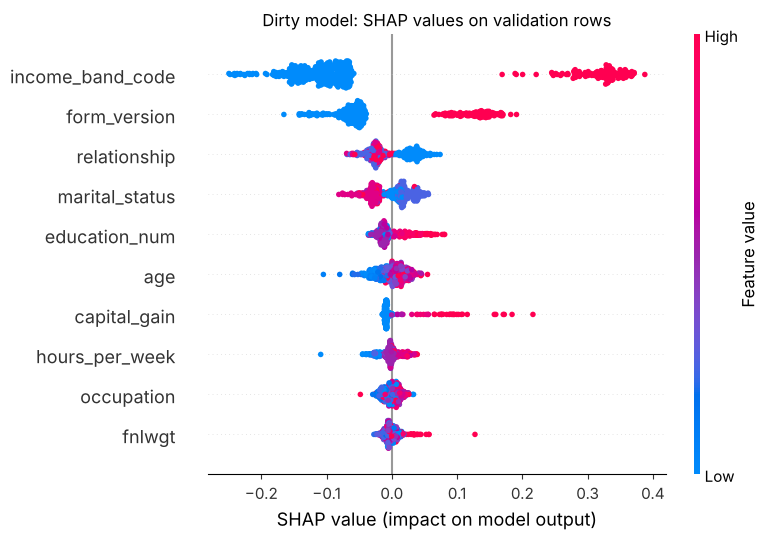

In [14]:
shap.summary_plot(dirty_phi, explain_rows, max_display=10, show=False)
plt.title("Dirty model: SHAP values on validation rows")
plt.tight_layout()
plt.show()

# 18. Diagnose {.scrollable}

Investigate the two suspicious features with **data questions**, not model questions [@kaufman2012leakage; @geirhos2020shortcut]:

| Question | `income_band_code` | `form_version` |
| --- | --- | --- |
| When is it recorded, before or after the outcome? | ? | ? |
| Is it available, with the same meaning, for new respondents? | ? | ? |
| Does its relation with the label hold outside the historical data? | ? | ? |

The next cell compares each feature's agreement with the label in validation and deployment.

In [15]:
for column in ["income_band_code", "form_version"]:
    print(column)
    print("  validation:", pd.crosstab(valid_df[column], valid_df[target], normalize="index").round(2).to_dict("index"))
    print("  deployment:", pd.crosstab(deploy_df[column], deploy_df[target], normalize="index").round(2).to_dict("index"))

income_band_code
  validation: {0: {0: 0.99, 1: 0.01}, 1: {0: 0.12, 1: 0.88}}
  deployment: {-1: {0: 0.75, 1: 0.25}}
form_version
  validation: {0: {0: 0.95, 1: 0.05}, 1: {0: 0.32, 1: 0.68}}
  deployment: {0: {0: 0.74, 1: 0.26}, 1: {0: 0.75, 1: 0.25}}


# 19. Fix the data, not the model {.scrollable}

`income_band_code` is **leakage** (recorded after the outcome, unavailable at prediction time). `form_version` is a **shortcut** (an artifact of how the historical data was collected). Remove both and retrain.

In [16]:
clean_cols = [c for c in feature_cols if c not in ("income_band_code", "form_version")]
X_tr_c, X_va_c, X_de_c = X_tr[clean_cols], X_va[clean_cols], X_de[clean_cols]

clean_model = fit_forest(X_tr_c, y_tr)
pd.DataFrame({
    ("dirty", "validation"): scores(dirty_model, X_va, y_va),
    ("dirty", "deployment"): scores(dirty_model, X_de, y_de),
    ("clean", "validation"): scores(clean_model, X_va_c, y_va),
    ("clean", "deployment"): scores(clean_model, X_de_c, y_de),
}).round(3)

dirty                 clean           
                  validation deployment validation deployment
balanced_accuracy      0.961      0.509      0.751      0.758
roc_auc                0.995      0.724      0.906      0.903
f1                     0.944      0.035      0.649      0.658

# Checkpoint: leakage and shortcuts

1. Validation got *worse* after the fix. Why is this the better model?
2. Which explanation (SHAP or permutation importance) made the problem easier to see?
3. Write one data-collection rule that would have prevented each problem.

# Part C: label errors

# 20. Out-of-fold predictions flag suspicious labels {.scrollable}

Confident learning compares **out-of-sample** predicted probabilities with the given labels [@northcutt2021confident]. A simple version: compute the out-of-fold probability of the *observed* label (*self-confidence*) and inspect the least confident examples. (The `cleanlab` library implements the full method.)

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(
    RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    X_tr_c, y_tr, cv=cv, method="predict_proba",
)
self_confidence = oof_proba[np.arange(len(y_tr)), y_tr.to_numpy()]

n_flag = int(0.10 * len(y_tr))
flag_idx = np.argsort(self_confidence)[:n_flag]
flagged = np.zeros(len(y_tr), dtype=bool)
flagged[flag_idx] = True

# The planted flips are known only because we injected them.
precision = (flagged & flipped).sum() / flagged.sum()
recall = (flagged & flipped).sum() / flipped.sum()
print(f"flagged {flagged.sum()} of {len(y_tr)} training rows")
print(f"precision vs planted flips: {precision:.2f}   recall: {recall:.2f}   (random flagging: {flipped.mean():.2f})")

flagged 400 of 4000 training rows
precision vs planted flips: 0.60   recall: 0.63   (random flagging: 0.10)


# 21. Inspect a flagged example {.scrollable}

A local explanation helps decide whether the **label** or the **model** is wrong: sensible attributions that strongly contradict the label suggest a label error.

observed label: 1   out-of-fold P(observed label) = 0.02


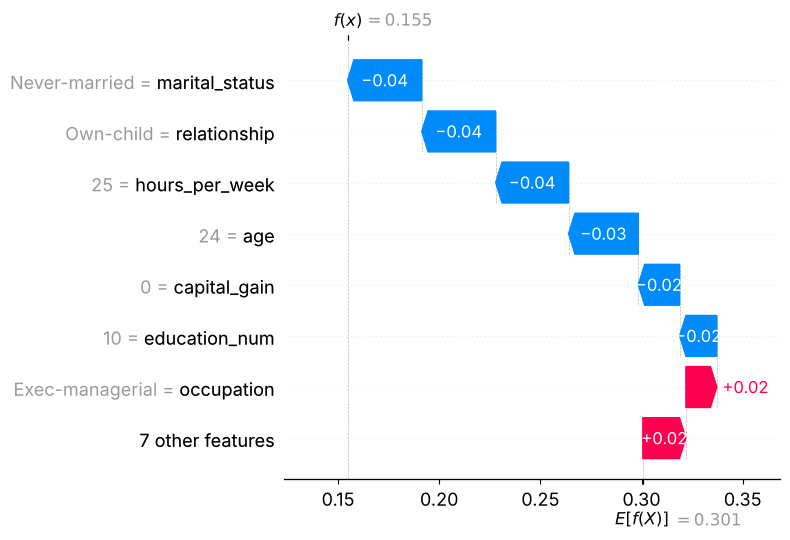

In [18]:
clean_explainer = shap.TreeExplainer(clean_model)
example = flag_idx[0]
example_phi = np.asarray(clean_explainer.shap_values(X_tr_c.iloc[[example]]))
example_phi = (example_phi[..., 1] if example_phi.ndim == 3 else example_phi).ravel()
base = np.asarray(clean_explainer.expected_value)
base = float(base[1] if base.size > 1 else base.item())

print(f"observed label: {y_tr.iloc[example]}   out-of-fold P(observed label) = {self_confidence[example]:.2f}")
shap.plots.waterfall(shap.Explanation(values=example_phi, base_values=base,
                                      data=train_df.loc[example, clean_cols].to_numpy(),
                                      feature_names=clean_cols), max_display=8, show=False)
plt.tight_layout()
plt.show()

# 22. Clean the labels and retrain {.scrollable}


In [19]:
keep = ~flagged
relabeled = y_tr.copy()
relabeled[flagged] = 1 - relabeled[flagged]

label_results = {
    "noisy labels": scores(fit_forest(X_tr_c, y_tr), X_de_c, y_de),
    "drop flagged": scores(fit_forest(X_tr_c[keep], y_tr[keep]), X_de_c, y_de),
    "relabel flagged": scores(fit_forest(X_tr_c, relabeled), X_de_c, y_de),
    "true labels (oracle)": scores(fit_forest(X_tr_c, true_train_labels), X_de_c, y_de),
}
pd.DataFrame(label_results).T.round(3)

,balanced_accuracy,roc_auc,f1
noisy labels,0.758,0.903,0.658
drop flagged,0.760,0.903,0.664
relabel flagged,0.754,0.901,0.654
true labels (oracle),0.757,0.911,0.657


# Checkpoint: label noise

Random forests are fairly robust to 10% symmetric noise, so the gain may be small. When would label errors matter more? (Think of systematic errors in one subgroup, small datasets, or evaluation labels.)

# Part D: data valuation with KNN-Shapley

# 23. Shapley values for training points {.scrollable}

Data Shapley treats **training points as players** and model performance as the payout [@ghorbani2019data]. For a $K$-nearest-neighbour classifier, exact values follow from a recursion [@jia2019efficient]. For one validation point, sort the $N$ training points by distance ($\alpha_1$ closest):

$$
s_{\alpha_N} = \frac{\mathbb{1}[y_{\alpha_N} = y]}{N}, \qquad
s_{\alpha_i} = s_{\alpha_{i+1}} + \frac{\mathbb{1}[y_{\alpha_i} = y] - \mathbb{1}[y_{\alpha_{i+1}} = y]}{K}\cdot\frac{\min(K, i)}{i}
$$

The value of a training point is the average over validation points.

In [20]:
def knn_shapley(X_train_arr, y_train_arr, X_valid_arr, y_valid_arr, k=10):
    n = len(y_train_arr)
    values = np.zeros(n)
    for x_v, y_v in zip(X_valid_arr, y_valid_arr):
        order = np.argsort(((X_train_arr - x_v) ** 2).sum(axis=1))
        match = (y_train_arr[order] == y_v).astype(float)
        s = np.zeros(n)
        s[n - 1] = match[n - 1] / n
        for i in range(n - 2, -1, -1):
            s[i] = s[i + 1] + (match[i] - match[i + 1]) / k * min(k, i + 1) / (i + 1)
        values[order] += s
    return values / len(y_valid_arr)


# Standardize numeric features and one-hot encode categoricals for meaningful distances.
design = pd.get_dummies(pd.concat([train_df[clean_cols], valid_df[clean_cols]]), dtype=float)
design = (design - design.iloc[: len(train_df)].mean()) / (design.iloc[: len(train_df)].std() + 1e-9)
D_tr, D_va = design.iloc[: len(train_df)].to_numpy(), design.iloc[len(train_df):].to_numpy()

valuation_idx = np.random.default_rng(RANDOM_STATE).choice(len(D_va), 400, replace=False)
data_values = knn_shapley(D_tr, y_tr.to_numpy(), D_va[valuation_idx], y_va.to_numpy()[valuation_idx])

pd.DataFrame({"mean value": [data_values[~flipped].mean(), data_values[flipped].mean()],
              "share with negative value": [(data_values[~flipped] < 0).mean(), (data_values[flipped] < 0).mean()]},
             index=["correct label", "flipped label"]).round(5)

,mean value,share with negative value
correct label,0.00023,0.15068
flipped label,-0.00037,0.69452


# 24. Do low-value points really hurt? {.scrollable}

Remove an increasing fraction of training points, retrain the random forest, and measure deployment performance. Three strategies:

- **lowest value (global)**: remove the lowest-valued points overall;
- **lowest value per class**: remove the same fraction of lowest-valued points *within each class*;
- **random**: remove random points.

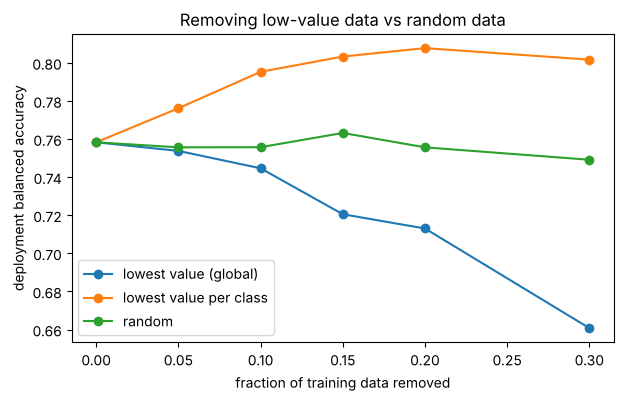

,removed,strategy,positives_in_removed,flipped_in_removed,balanced_accuracy,roc_auc,f1
0,0.00,lowest value (global),NaN,NaN,0.758,0.903,0.658
1,0.00,lowest value per class,NaN,NaN,0.758,0.903,0.658
2,0.00,random,NaN,NaN,0.758,0.903,0.658
3,0.05,lowest value (global),1.000,0.540,0.754,0.898,0.653
4,0.05,lowest value per class,0.302,0.352,0.776,0.903,0.680
5,0.05,random,0.350,0.100,0.756,0.900,0.653
6,0.10,lowest value (global),0.940,0.418,0.745,0.889,0.640
7,0.10,lowest value per class,0.301,0.293,0.795,0.902,0.701
8,0.10,random,0.332,0.105,0.756,0.900,0.655
9,0.15,lowest value (global),0.913,0.365,0.721,0.880,0.601


In [21]:
fractions = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30]
labels = y_tr.to_numpy()


def removal_set(strategy, frac):
    if strategy == "lowest value (global)":
        return np.argsort(data_values)[: int(frac * len(data_values))]
    if strategy == "lowest value per class":
        removed = []
        for cls in np.unique(labels):
            ids = np.where(labels == cls)[0]
            removed.extend(ids[np.argsort(data_values[ids])[: int(frac * len(ids))]])
        return np.array(removed, dtype=int)
    return np.random.default_rng(RANDOM_STATE).permutation(len(data_values))[: int(frac * len(data_values))]


rows = []
for frac in fractions:
    for name in ["lowest value (global)", "lowest value per class", "random"]:
        removed_idx = removal_set(name, frac)
        keep_idx = np.setdiff1d(np.arange(len(data_values)), removed_idx)
        model = fit_forest(X_tr_c.iloc[keep_idx], y_tr.iloc[keep_idx])
        rows.append({"removed": frac, "strategy": name,
                     "positives_in_removed": labels[removed_idx].mean() if len(removed_idx) else np.nan,
                     "flipped_in_removed": flipped[removed_idx].mean() if len(removed_idx) else np.nan,
                     **scores(model, X_de_c, y_de)})
removal = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for name, group in removal.groupby("strategy"):
    ax.plot(group["removed"], group["balanced_accuracy"], marker="o", label=name)
ax.set_xlabel("fraction of training data removed")
ax.set_ylabel("deployment balanced accuracy")
ax.set_title("Removing low-value data vs random data")
ax.legend()
plt.show()
removal.round(3)

# Checkpoint: data values

1. Are flipped labels concentrated among the lowest-valued points? Why does a KNN utility detect them?
2. Why does global removal hurt? Look at `positives_in_removed`: the minority class has lower KNN values, so global removal deletes positives. What does this say about valuing data under class imbalance?
3. The values come from a KNN model but we retrain a random forest: what could go wrong?
4. How would you use data values to decide **which new data to collect**?

# Part E: counterfactuals and proxies

# 25. A minimal counterfactual search {.scrollable}

For a respondent predicted at most 50K, search the smallest change to **actionable** features that flips the prediction [@wachter2017counterfactual; @mothilal2020explaining]. Here: weekly hours (+0 to +20) and years of education (+0 to +4).

In [22]:
deploy_pred = clean_model.predict(X_de_c)
candidates = np.where((deploy_pred == 0) & (deploy_df["age"] < 50))[0]


def counterfactual(row):
    grid = [(e, h) for e in range(0, 5) for h in range(0, 21, 2)]
    variants = pd.DataFrame([row] * len(grid)).reset_index(drop=True)
    variants["education_num"] = [min(16, row["education_num"] + e) for e, _ in grid]
    variants["hours_per_week"] = [min(99, row["hours_per_week"] + h) for _, h in grid]
    flips = clean_model.predict(variants) == 1
    if not flips.any():
        return None
    costs = [e / 4 + h / 20 if f else np.inf for (e, h), f in zip(grid, flips)]
    best = int(np.argmin(costs))
    return costs[best], grid[best][0], grid[best][1]


found = []
for i in candidates[:200]:
    result = counterfactual(X_de_c.iloc[i])
    if result is not None:
        found.append({"respondent": i, "extra_education_years": result[1], "extra_weekly_hours": result[2]})
print(f"counterfactual found for {len(found)} of {min(200, len(candidates))} respondents")
pd.DataFrame(found).head(8)

counterfactual found for 45 of 200 respondents


,respondent,extra_education_years,extra_weekly_hours
0,13,1,0
1,23,3,0
2,27,4,0
3,30,4,0
4,31,2,0
5,37,4,8
6,38,2,4
7,53,3,0


# 26. Proxy check: what if only marital status changed? {.scrollable}

`marital_status` and `relationship` are not actionable, and they are strongly associated with sex (`Husband` is 100% male, `Wife` 100% female). If changing them alone flips decisions, the model relies on **proxies**, and counterfactuals built on them are not acceptable recourse.

In [23]:
married_code = category_maps["marital_status"].get("Married-civ-spouse")
husband_code = category_maps["relationship"].get("Husband")
rejected = X_de_c.iloc[candidates[:200]].copy()
what_if = rejected.copy()
what_if["marital_status"] = married_code
what_if["relationship"] = husband_code
flip_rate = clean_model.predict(what_if).mean()
print(f"Share of rejected respondents whose prediction flips when only marital status/relationship change: {flip_rate:.2f}")
display(pd.crosstab(train_df["relationship"], train_df["sex"], normalize="index").round(2))

Share of rejected respondents whose prediction flips when only marital status/relationship change: 0.06


sex,Female,Male
relationship,,
Husband,0.00,1.00
Not-in-family,0.46,0.54
Other-relative,0.42,0.58
Own-child,0.46,0.54
Unmarried,0.79,0.21
Wife,1.00,0.00


# Checkpoint: counterfactuals

1. Which counterfactuals are *plausible* and *actionable* for a real person?
2. What does the proxy check tell you about the data, and how does it connect to the fairness lab?

# Deliverable: a data bug report

For each problem you found (leakage, shortcut, label errors, proxies), write:

1. **Symptom**: what you observed (metrics, attributions, data values).
2. **Explanation used**: which method revealed it, and why it worked.
3. **Root cause in the data**: how the data was collected or recorded.
4. **Fix**: what you changed in the data, and the effect on deployment performance.
5. **Residual risk**: what the explanations *cannot* tell you.

# Extension tasks

- Replace the random forest with a logistic regression and compare `LinearExplainer` values with $\beta_j (x_j - E[X_j])$.
- Compute SHAP interaction values (`shap_interaction_values`) for the flight tree and find the strongest pair.
- Run `cleanlab.find_label_issues` and compare it with the self-confidence ranking.
- Compute KNN-Shapley values separately for men and women: is low-value data concentrated in one group?
- Use `dice-ml` to generate diverse counterfactuals and compare them with the grid search.

# References {.scrollable}

::: {#refs}
:::